# Maximum flow: shortest augmenting path vs preflow-push on all 14 datasets

**Abhimanyu Sharotry**  
MMIE 7372 Network Flows and Dynamic Programming, Fall 2026: Computational Study 2  
November 10, 2026

**Assignment.** Compare (1) shortest augmenting path and (2) preflow-push, two algorithms for the maximum flow problem, on all of the datasets for Computational Study 2

## Summary

**As observed in the course, shortest augmenting path (SAP) was usually faster than preflow-push on these networks.** Each comparison was repeated with 30 shuffled orders of each room's passage list. SAP was clearly faster than FIFO preflow-push on 10 of the 13 data cases that carry flow, taking 8% to 32% less time. Preflow-push was clearly faster on 2 (`elist160d` and `elist500d`, where SAP took 11% and 72% longer), and `elist640d` was a dead heat.

**With each algorithm's standard speed-ups switched on, the result flips.** Preflow-push with gap and global relabeling was clearly faster on 9 of the 13, including all 6 dense files, where SAP with its `numb` early stop took 1.7 to 4.7 times as long.

**Why.** Both algorithms spend most of their effort after the answer is already reached: SAP proving that no route is left, preflow-push raising room labels until the people who cannot get out can walk back. That shared waste keeps their totals close, and SAP's steps are cheaper. The speed-ups remove almost all of the waste. What is left is the work of finding the flow, where SAP does 1.7 to 3.7 times as much work as preflow-push on the dense files.

On the 8 files with no route from start to exit, both algorithms finish in under 0.2 ms. The worst-case bounds, O(n²m) for SAP against O(n³) for FIFO, did not predict the winner. The master table is in Section 6.

## Setup

The next three cells load the libraries, the file reader, and the 14 data files. Capacities are read as exact whole numbers (each multiplied by 10⁴; every file has at most 4 decimals), so no rounding error can enter.

In [1]:
# Setup: libraries, plot style, and where the study's saved results live (used in Section 6 only).
import gc
import hashlib
import io
import os
import random
import statistics
import sys
import time
import zipfile
from dataclasses import asdict
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

REPO = "https://github.com/absharotry/mmie.7372.001.NetFlow-DyProg.fall26/tree/main/computational-study-2"
RAW = "https://raw.githubusercontent.com/absharotry/mmie.7372.001.NetFlow-DyProg.fall26/main/computational-study-2"

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, BASE, ROOM, BAND = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#b4b2a9", "#f1efe8"
plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 10, "axes.edgecolor": BASE, "axes.labelcolor": INK2,
    "axes.titlesize": 11, "axes.titlecolor": INK, "text.color": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
pd.set_option("display.max_columns", 40, "display.width", 200)
print("Python", sys.version.split()[0], "| NetworkX", nx.__version__, "| pandas", pd.__version__)

Python 3.13.18 | NetworkX 3.7 | pandas 2.2.3


In [2]:
# ---- copied from src/maxflow/instance.py (tested in the study's repository) ----
"""Read one elist data file into a checked list of arcs.

Building language (docs/plan_of_action.md, Section 5): rooms are nodes, passages are arcs, the start
room is the source s and the exit room is the sink t. Capacity ("people per minute") has no units.

Decisions applied here (docs/data_modeling.md, Section 9):
- DM1: every file is used exactly as given and read as directed.
- DM2, DM3: the two-way reading is a separate option, allowed only for files with no two-way pairs.
- DM4: capacities become exact integers by multiplying by 10**4, which meets AMO Assumption 6.2.
"""

from __future__ import annotations

from decimal import Decimal, InvalidOperation
from pathlib import Path
from typing import NamedTuple

# Every capacity in the data has at most 4 decimal places, so this makes all of them whole numbers.
SCALE = 10_000

DIRECTED = "directed"
TWO_WAY = "two-way"

SIZES = (96, 160, 200, 500, 640, 960, 1440)
SPARSE = tuple(f"elist{size}" for size in SIZES)
DENSE = tuple(f"elist{size}d" for size in SIZES if size != 1440)  # the 6 files that carry flow
DATASETS = tuple(name for size in SIZES for name in (f"elist{size}", f"elist{size}d"))


class DataError(ValueError):
    """A data file breaks a rule the study relies on. The message names the rule."""


class Arc(NamedTuple):
    tail: int  # room the passage leaves
    head: int  # room the passage enters
    capacity: int  # exact integer: the file's capacity times SCALE


class Instance(NamedTuple):
    name: str
    n: int  # number of rooms
    s: int  # start room (source)
    t: int  # exit room (sink)
    arcs: tuple[Arc, ...]  # in file order, which is the baseline arc order (DM8)
    reading: str  # DIRECTED or TWO_WAY

    @property
    def m(self) -> int:
        """Number of arcs the algorithms will see."""
        return len(self.arcs)


def parse_capacity(text: str) -> int:
    """Turn capacity text into an exact integer (times SCALE), without any floating-point step.

    The files mix formats such as '3.200100e+00', '3.20010' and '8.86000E-02'. Decimal reads all of
    them exactly, so 3.2001 becomes exactly 32001. Rounding is never used: a value that is not a
    whole number after scaling is an error.
    """
    try:
        value = Decimal(text)
    except InvalidOperation:
        raise DataError(f"capacity {text!r} is not a number") from None
    if not value.is_finite():
        raise DataError(f"capacity {text!r} is not a finite number")
    scaled = value * SCALE
    if scaled != scaled.to_integral_value():
        raise DataError(f"capacity {text!r} has more than 4 decimal places")
    if scaled <= 0:
        raise DataError(f"capacity {text!r} is not positive")
    return int(scaled)


def to_text(scaled: int) -> str:
    """Show a scaled integer in the file's own units, for example 13784 -> '1.3784', 0 -> '0'."""
    return format((Decimal(scaled) / SCALE).normalize(), "f")


def _parse_int(text: str, what: str) -> int:
    try:
        return int(text)
    except ValueError:
        raise DataError(f"{what} {text!r} is not a whole number") from None


def parse_elist(text: str, name: str) -> Instance:
    """Read the text of one file and audit it (docs/data_modeling.md, Section 3).

    Format: n, m, s, t, then one 'tail head capacity' triple per arc. Values are split on any
    whitespace, so irregular spacing and CRLF line endings do not matter.
    """
    tokens = text.split()
    if len(tokens) < 4:
        raise DataError(f"{name}: the header needs four numbers: n, m, s and t")
    n = _parse_int(tokens[0], "room count n")
    m = _parse_int(tokens[1], "arc count m")
    s = _parse_int(tokens[2], "start room s")
    t = _parse_int(tokens[3], "exit room t")
    if n < 2:
        raise DataError(f"{name}: needs at least 2 rooms, header says {n}")
    if not (1 <= s <= n and 1 <= t <= n):
        raise DataError(f"{name}: start {s} or exit {t} is outside rooms 1..{n}")
    if s == t:
        raise DataError(f"{name}: start and exit are the same room {s}")

    body = tokens[4:]
    if len(body) % 3:
        raise DataError(f"{name}: every arc needs 3 values (tail head capacity); {len(body) % 3} left over")
    if len(body) // 3 != m:
        raise DataError(f"{name}: header says {m} arcs but the file lists {len(body) // 3}")

    arcs: list[Arc] = []
    seen: set[tuple[int, int]] = set()
    for i in range(0, len(body), 3):
        number = i // 3 + 1
        u = _parse_int(body[i], f"arc {number} tail")
        v = _parse_int(body[i + 1], f"arc {number} head")
        if not (1 <= u <= n and 1 <= v <= n):
            raise DataError(f"{name}: arc {number} ({u}, {v}) uses a room outside 1..{n}")
        if u == v:
            raise DataError(f"{name}: arc {number} is a self-loop at room {u}")
        if (u, v) in seen:
            raise DataError(f"{name}: arc {number} ({u}, {v}) is listed twice (AMO Assumption 6.5)")
        seen.add((u, v))
        try:
            capacity = parse_capacity(body[i + 2])
        except DataError as err:
            raise DataError(f"{name}: arc {number} ({u}, {v}): {err}") from None
        arcs.append(Arc(u, v, capacity))
    return Instance(name, n, s, t, tuple(arcs), DIRECTED)


def to_two_way(instance: Instance) -> Instance:
    """Read every passage as usable in both directions (AMO Section 2.4, p. 39).

    Each edge {i, j} of capacity u becomes arcs (i, j) and (j, i), both of capacity u. Flows in
    opposite directions cancel, so at most u people per minute cross in net. The new arcs follow
    file order, each forward arc followed by its reverse.

    Allowed only when no node pair is already listed in both directions (DM3): such a pair would
    need a rule for combining two capacities, and the data does not give one.
    """
    if instance.reading != DIRECTED:
        raise ValueError(f"{instance.name} is already read as {instance.reading}")
    pairs = {(arc.tail, arc.head) for arc in instance.arcs}
    doubled = sum(1 for (u, v) in pairs if u < v and (v, u) in pairs)
    if doubled:
        raise DataError(
            f"{instance.name} already lists {doubled} node pairs in both directions; reading it as "
            "two-way would need a rule for combining their capacities (DM3)"
        )
    arcs: list[Arc] = []
    for arc in instance.arcs:
        arcs.append(arc)
        arcs.append(Arc(arc.head, arc.tail, arc.capacity))
    return instance._replace(arcs=tuple(arcs), reading=TWO_WAY)


def read_instance(path: str | Path, reading: str = DIRECTED) -> Instance:
    """Read and audit one data file, in the directed reading (default) or the two-way reading."""
    path = Path(path)
    instance = parse_elist(path.read_text(encoding="ascii"), path.stem)
    if reading == DIRECTED:
        return instance
    if reading == TWO_WAY:
        return to_two_way(instance)
    raise ValueError(f"unknown reading {reading!r}; use {DIRECTED!r} or {TWO_WAY!r}")

In [3]:
# Load the 14 data files from your Google Drive folder.
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
DATA_DIR = Path("/content/drive/MyDrive/Colab Notebooks/MMIE7372-ComputationAssignment2-Sharotry/Data")  # <- your Data folder's path

# Sanity check: every file is present, reads without errors, and has the expected rooms (n) and
# passages (m). The reader also checks that each file lists exactly m arcs, every arc joins rooms
# 1..n, and every capacity is a positive number.
EXPECTED = {  # file: (n, m)
    "elist96": (96, 187), "elist96d": (96, 528), "elist160": (160, 285), "elist160d": (160, 912),
    "elist200": (200, 483), "elist200d": (200, 1340), "elist500": (500, 1040), "elist500d": (500, 3975),
    "elist640": (640, 3037), "elist640d": (640, 12608), "elist960": (960, 2061), "elist960d": (960, 9488),
    "elist1440": (1440, 5397), "elist1440d": (1440, 5397),
}
missing = [name for name in EXPECTED if not (DATA_DIR / f"{name}.txt").exists()]
assert not missing, f"missing from {DATA_DIR}: {', '.join(missing)}"
for name, (n, m) in EXPECTED.items():
    inst = read_instance(DATA_DIR / f"{name}.txt")
    assert (inst.n, inst.m) == (n, m), f"{name}: expected n = {n}, m = {m}, found n = {inst.n}, m = {inst.m}"
    print(f"{name:<11} n = {inst.n:>5}   m = {inst.m:>6}   ok")
print(f"All 14 files found in {DATA_DIR}, read without errors, and match the expected sizes.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
elist96     n =    96   m =    187   ok
elist96d    n =    96   m =    528   ok
elist160    n =   160   m =    285   ok
elist160d   n =   160   m =    912   ok
elist200    n =   200   m =    483   ok
elist200d   n =   200   m =   1340   ok
elist500    n =   500   m =   1040   ok
elist500d   n =   500   m =   3975   ok
elist640    n =   640   m =   3037   ok
elist640d   n =   640   m =  12608   ok
elist960    n =   960   m =   2061   ok
elist960d   n =   960   m =   9488   ok
elist1440   n =  1440   m =   5397   ok
elist1440d  n =  1440   m =   5397   ok
All 14 files found in /content/drive/MyDrive/Colab Notebooks/MMIE7372-ComputationAssignment2-Sharotry/Data, read without errors, and match the expected sizes.


## 1. Quick overview of the data

For this study, we visualize the files as **buildings**: rooms are nodes, passages are arcs, and a passage's capacity is how many people per minute it can carry (capacities have no units). People enter at a start room *s* and leave at an exit room *t*. The max flow is how many people per minute can get out.

- **Six dense files** (`elist96d` to `elist960d`) are buildings of **floors**. Each floor is a square grid of rooms joined by two-way **corridors** of one large capacity; **stairs** of small capacity join neighbouring floors. The start is a corner room of the first floor and the exit a corner room of the last.
- **Seven sparse files** have the same numbers of rooms but far fewer passages (about 2 to 5 per room instead of 5.5 to 19.7), all one-way.
- `elist1440d` is the same file as the sparse `elist1440`.

The cell below (from the study's analysis module, never used by the algorithms) finds the floors from the passages alone.

In [4]:
# ---- copied from src/maxflow/structure.py (tested in the study's repository) ----
"""Describe a network's structure: counts, reachability and floors. Analysis only.
NetworkX used as an independent reference (max flow, grid matching). It is never one of
the algorithms being compared.
"""

from __future__ import annotations

import math
from collections import deque
from dataclasses import dataclass

import networkx as nx


# ---------------------------------------------------------------------------------------------
# Reachability: which rooms can the start reach, and which rooms can reach the exit?
# ---------------------------------------------------------------------------------------------

def _neighbours(instance: Instance, backward: bool = False) -> dict[int, list[int]]:
    nbrs: dict[int, list[int]] = {room: [] for room in range(1, instance.n + 1)}
    for arc in instance.arcs:
        if backward:
            nbrs[arc.head].append(arc.tail)
        else:
            nbrs[arc.tail].append(arc.head)
    return nbrs


def _breadth_first(nbrs: dict[int, list[int]], start: int) -> dict[int, int]:
    """Number of passages from start to every room it can reach (breadth-first search)."""
    dist = {start: 0}
    queue = deque([start])
    while queue:
        room = queue.popleft()
        for nxt in nbrs[room]:
            if nxt not in dist:
                dist[nxt] = dist[room] + 1
                queue.append(nxt)
    return dist


def reachable_from(instance: Instance, room: int) -> set[int]:
    """Rooms that can be reached from `room` (including itself)."""
    return set(_breadth_first(_neighbours(instance), room))


def shortest_route(instance: Instance) -> int | None:
    """Fewest passages on any route from start to exit, or None if there is no route.

    Every augmenting path the shortest augmenting path algorithm finds is at least this long,
    because distance labels never decrease (AMO Lemma 7.5).
    """
    return _breadth_first(_neighbours(instance), instance.s).get(instance.t)


def source_flood(instance: Instance) -> int:
    """Total capacity out of the start: what preflow-push sends out first (AMO Figure 7.11)."""
    return sum(arc.capacity for arc in instance.arcs if arc.tail == instance.s)


def reference_max_flow(instance: Instance) -> int:
    """Max flow from NetworkX on the exact integer capacities. An independent reference only."""
    graph = nx.DiGraph()
    graph.add_nodes_from(range(1, instance.n + 1))
    graph.add_weighted_edges_from(instance.arcs, weight="capacity")
    return nx.maximum_flow_value(graph, instance.s, instance.t)


# ---------------------------------------------------------------------------------------------
# Floors: the structure of the dense files (docs/data_modeling.md, Section 7)
# ---------------------------------------------------------------------------------------------

@dataclass(frozen=True, eq=False)
class Floors:
    count: int  # number of floors L
    side: int  # each floor is a side x side grid of rooms
    corridor_capacity: int  # U, the one capacity shared by every corridor
    floor_of: dict[int, int]  # room -> floor number, 0 = the start's floor
    position: dict[int, tuple[int, int]]  # room -> (row, column) inside its floor's grid
    up_totals: tuple[int, ...]  # F_k: total up-stair capacity from floor k to floor k + 1
    up_stairs: int  # number of stairs going one floor up
    down_stairs: int  # number of stairs going one floor down

    @property
    def rooms_per_floor(self) -> int:
        return self.side * self.side

    @property
    def up_per_room(self) -> float:
        return self.up_stairs / (self.rooms_per_floor * (self.count - 1))

    @property
    def down_per_room(self) -> float:
        return self.down_stairs / (self.rooms_per_floor * (self.count - 1))

    @property
    def narrowest_gap(self) -> int:
        """Index k of the narrowest gap: k = 0 means the stairs from floor 1 to floor 2."""
        return min(range(len(self.up_totals)), key=self.up_totals.__getitem__)

    @property
    def stair_sum_max_flow(self) -> int:
        """Max flow by adding up stairs: min over k of F_k (the Proposition, data_modeling.md 7)."""
        return min(self.up_totals)

    @property
    def proposition_holds(self) -> bool:
        """The Proposition needs min F_k <= U, so that no corridor can be the limit."""
        return self.stair_sum_max_flow <= self.corridor_capacity


def find_floors(instance: Instance) -> Floors | None:
    """Find the chain of grid floors, or return None if the network is not built that way.

    Steps:
    1. Corridors are the arcs with the largest capacity U, and each must run both ways.
    2. Rooms joined by corridors form the floors; every floor must be an exact grid of one size.
    3. All other arcs are stairs. They must link the floors into a single chain that starts at the
       start's floor, and every stair must join neighbouring floors.
    Sparse files fail step 2, because some stairs were widened to U and floors merge together.
    """
    corridor_capacity = max(arc.capacity for arc in instance.arcs)
    corridors = {(arc.tail, arc.head) for arc in instance.arcs if arc.capacity == corridor_capacity}
    if any((v, u) not in corridors for (u, v) in corridors):
        return None

    corridor_graph = nx.Graph()
    corridor_graph.add_nodes_from(range(1, instance.n + 1))
    corridor_graph.add_edges_from(corridors)
    groups = [set(group) for group in nx.connected_components(corridor_graph)]
    size = len(groups[0])
    side = math.isqrt(size)
    if side < 2 or side * side != size or any(len(group) != size for group in groups):
        return None

    grid = nx.grid_2d_graph(side, side)
    position: dict[int, tuple[int, int]] = {}
    for group in groups:
        matcher = nx.isomorphism.GraphMatcher(corridor_graph.subgraph(group), grid)
        if not matcher.is_isomorphic():
            return None
        position.update(matcher.mapping)

    group_of = {room: g for g, group in enumerate(groups) for room in group}
    stairs = [arc for arc in instance.arcs if arc.capacity != corridor_capacity]
    chain = nx.Graph()
    chain.add_nodes_from(range(len(groups)))
    chain.add_edges_from((group_of[a.tail], group_of[a.head]) for a in stairs)
    start_group = group_of[instance.s]
    if not nx.is_isomorphic(chain, nx.path_graph(len(groups))):
        return None
    if len(groups) > 1 and chain.degree(start_group) != 1:
        return None
    order = nx.single_source_shortest_path_length(chain, start_group)
    floor_of = {room: order[group_of[room]] for room in group_of}

    count = len(groups)
    up_totals = [0] * (count - 1)
    up = down = 0
    for arc in stairs:
        step = floor_of[arc.head] - floor_of[arc.tail]
        if step == 1:
            up_totals[floor_of[arc.tail]] += arc.capacity
            up += 1
        elif step == -1:
            down += 1
        else:
            return None
    return Floors(count, side, corridor_capacity, floor_of, position, tuple(up_totals), up, down)

In [5]:
# Read all 14 files as given (directed), and the 7 sparse files a second time as two-way.
directed = {name: read_instance(DATA_DIR / f"{name}.txt") for name in DATASETS}
CASES = [(name, DIRECTED) for name in DATASETS] + [(name, TWO_WAY) for name in SPARSE]
instances = {(name, DIRECTED): directed[name] for name in DATASETS}
instances |= {(name, TWO_WAY): to_two_way(directed[name]) for name in SPARSE}
floors = {name: find_floors(directed[name]) for name in DATASETS}


def case_label(name, reading):
    return name if reading == DIRECTED else f"{name} (two-way)"


overview = pd.DataFrame([{
    "file": name,
    "rooms n": inst.n,
    "passages m": inst.m,
    "passages per room": round(inst.m / inst.n, 2),
    "building": (f"{floors[name].count} floors of {floors[name].side} x {floors[name].side} rooms"
                 if floors[name] else "no floor structure"),
} for name, inst in directed.items()]).set_index("file")
overview

,rooms n,passages m,passages per room,building
file,,,,
elist96,96,187,1.95,no floor structure
elist96d,96,528,5.50,6 floors of 4 x 4 rooms
elist160,160,285,1.78,no floor structure
elist160d,160,912,5.70,10 floors of 4 x 4 rooms
elist200,200,483,2.42,no floor structure
elist200d,200,1340,6.70,8 floors of 5 x 5 rooms
elist500,500,1040,2.08,no floor structure
elist500d,500,3975,7.95,20 floors of 5 x 5 rooms
elist640,640,3037,4.75,no floor structure


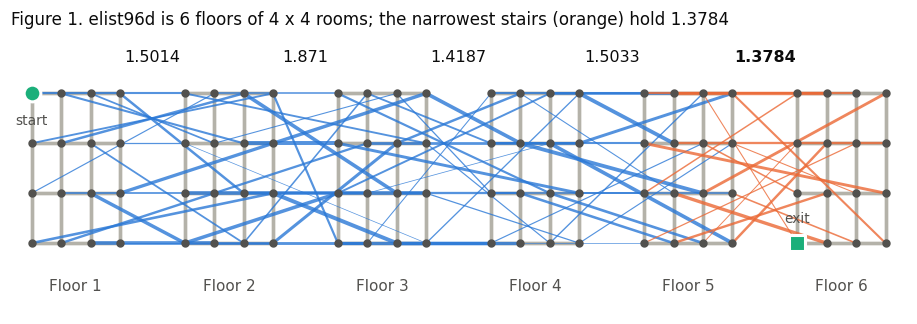

In [6]:
# Figure 1: elist96d drawn as a building.
FLOOR_STEP = 5.2


def building_xy(fl, room):
    row, col = fl.position[room]
    return row + fl.floor_of[room] * FLOOR_STEP, col


def figure_1():
    inst, fl = directed["elist96d"], floors["elist96d"]
    pos = {room: building_xy(fl, room) for room in fl.floor_of}
    gap = fl.narrowest_gap
    fig, ax = plt.subplots(figsize=(10.5, 3.3))
    for arc in inst.arcs:
        a, b = fl.floor_of[arc.tail], fl.floor_of[arc.head]
        if a == b:
            ax.plot(*zip(pos[arc.tail], pos[arc.head]), color=ROOM, lw=2.2, zorder=1, solid_capstyle="round")
        elif b > a:  # up stairs, thickness proportional to capacity; down stairs not drawn
            ax.plot(*zip(pos[arc.tail], pos[arc.head]), color=ORANGE if a == gap else BLUE,
                    lw=0.4 + arc.capacity / SCALE * 11, alpha=0.8, zorder=2)
    ax.scatter(*zip(*pos.values()), s=20, color=INK2, zorder=3)
    ax.scatter(*pos[inst.s], s=120, color=AQUA, edgecolor="white", lw=2, zorder=4)
    ax.scatter(*pos[inst.t], s=120, color=AQUA, marker="s", edgecolor="white", lw=2, zorder=4)
    for f in range(fl.count):
        ax.text(1.5 + f * FLOOR_STEP, -0.95, f"Floor {f + 1}", ha="center", color=INK2)
    for k, total in enumerate(fl.up_totals):
        ax.text(1.5 + k * FLOOR_STEP + FLOOR_STEP / 2, 3.65, to_text(total), ha="center", fontsize=10.5,
                fontweight="bold" if k == gap else "normal")
    for room, word in ((inst.s, "start"), (inst.t, "exit")):
        x, y = pos[room]
        ax.text(x, y + (0.42 if y < 3 else -0.62), word, ha="center", color=INK2, fontsize=9)
    ax.set_xlim(-0.7, 3 + (fl.count - 1) * FLOOR_STEP + 0.7)
    ax.set_ylim(-1.4, 4.2)
    ax.axis("off")
    ax.set_title(f"Figure 1. elist96d is {fl.count} floors of {fl.side} x {fl.side} rooms; the narrowest stairs "
                 f"(orange) hold {to_text(fl.stair_sum_max_flow)}", loc="left")
    plt.show()


figure_1()

## 2. Initial findings

- **Only 6 of the 14 files carry any flow:** the six dense buildings. In every sparse file the start reaches only a handful of rooms and never the exit (Figure 3), so the max flow is 0. The same holds for `elist1440d`.
- **On the dense files, the flow is set by the narrowest set of stairs.** Everyone must climb from each floor to the next, so the max flow cannot exceed the smallest stair total between neighbouring floors, and on every dense file it equals it (Figure 2). This gives a check on every answer that needs no algorithm.
- **A two-way supplement.** Because the sparse files carry nothing as given, they are also solved with every passage usable both ways. This adds 7 additional cases that carry flow, always reported as a separate, labelled block.

In total there are **21 data cases**: the 14 files as given and the 7 two-way readings. **13 carry flow**; the comparison of the algorithms rests on those.

In [7]:
# Max flow of every case from NetworkX (an independent reference, never timed), who can reach whom,
# and the floor check: on the dense files the max flow must equal the narrowest floor's stair total.
reference = {case: reference_max_flow(inst) for case, inst in instances.items()}
stair_sums = {(name, DIRECTED): fl.stair_sum_max_flow for name, fl in floors.items() if fl is not None}
assert all(floors[name].proposition_holds for (name, _) in stair_sums)
assert all(reference[case] == value for case, value in stair_sums.items())

findings = pd.DataFrame([{
    "case": case_label(*case),
    "max flow": to_text(reference[case]),
    "carries flow": "yes" if reference[case] else "no",
    "rooms the start can reach": f"{len(reachable_from(inst, inst.s))} of {inst.n}",
    "shortest route (passages)": shortest_route(inst) if shortest_route(inst) is not None else "none",
    "narrowest stairs": (f"floors {floors[case[0]].narrowest_gap + 1}-{floors[case[0]].narrowest_gap + 2}"
                         if case in stair_sums else ""),
} for case, inst in instances.items()]).set_index("case")
print(f"{sum(reference[c] > 0 for c in CASES if c[1] == DIRECTED)} of 14 files carry flow; "
      f"the stair sum equals the max flow on all {len(stair_sums)} dense files.")
findings

6 of 14 files carry flow; the stair sum equals the max flow on all 6 dense files.


,max flow,carries flow,rooms the start can reach,shortest route (passages),narrowest stairs
case,,,,,
elist96,0,no,4 of 96,none,
elist96d,1.3784,yes,96 of 96,5,floors 5-6
elist160,0,no,5 of 160,none,
elist160d,211.8491,yes,160 of 160,9,floors 2-3
elist200,0,no,4 of 200,none,
elist200d,2.1353,yes,200 of 200,9,floors 3-4
elist500,0,no,7 of 500,none,
elist500d,702.1112,yes,500 of 500,19,floors 1-2
elist640,0,no,11 of 640,none,


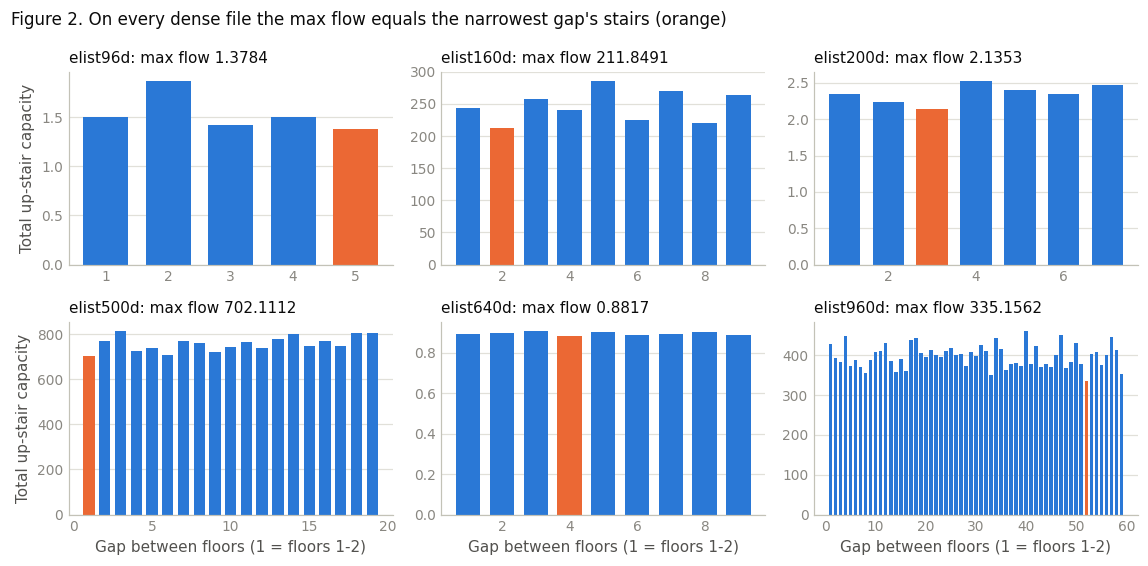

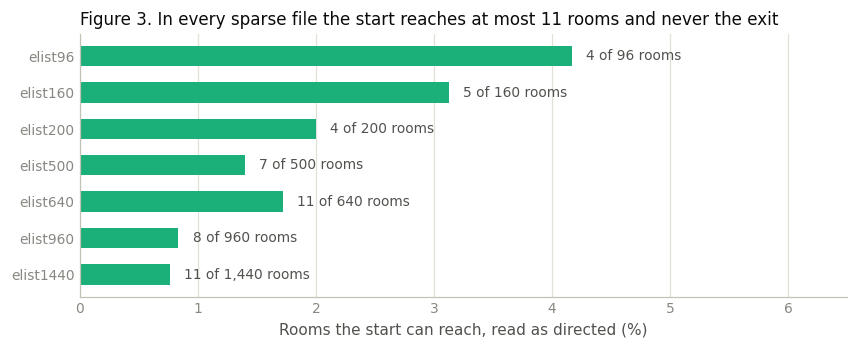

In [8]:
# Figure 2: the stair total between each pair of neighbouring floors. Figure 3: how far the start gets.
def figure_2():
    fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.2))
    for ax, name in zip(axes.flat, DENSE):
        fl = floors[name]
        values = [v / SCALE for v in fl.up_totals]
        gap = fl.narrowest_gap
        ax.bar(range(1, len(values) + 1), values, width=0.72, zorder=2,
               color=[ORANGE if k == gap else BLUE for k in range(len(values))])
        ax.set_title(f"{name}: max flow {to_text(fl.stair_sum_max_flow)}", loc="left", fontsize=10)
        ax.yaxis.grid(True, color=GRID, zorder=0)
        ax.tick_params(length=0)
    for ax in axes[1]:
        ax.set_xlabel("Gap between floors (1 = floors 1-2)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Total up-stair capacity")
    fig.suptitle("Figure 2. On every dense file the max flow equals the narrowest gap's stairs (orange)",
                 x=0.01, ha="left", fontsize=11)
    fig.tight_layout()
    plt.show()


def figure_3():
    rows = [(name, directed[name].n, len(reachable_from(directed[name], directed[name].s))) for name in SPARSE]
    fig, ax = plt.subplots(figsize=(9, 3.1))
    ys = list(range(len(rows)))[::-1]
    ax.barh(ys, [100 * r / n for _, n, r in rows], height=0.56, color=AQUA, zorder=2)
    for y, (_, n, r) in zip(ys, rows):
        ax.text(100 * r / n + 0.12, y, f"{r} of {n:,} rooms", va="center", fontsize=9, color=INK2)
    ax.set_yticks(ys)
    ax.set_yticklabels([name for name, _, _ in rows])
    ax.tick_params(length=0)
    ax.set_xlim(0, 6.5)
    ax.xaxis.grid(True, color=GRID, zorder=0)
    ax.set_xlabel("Rooms the start can reach, read as directed (%)")
    ax.set_title(f"Figure 3. In every sparse file the start reaches at most {max(r for _, _, r in rows)} rooms "
                 "and never the exit", loc="left")
    plt.show()


figure_2()
figure_3()

## 3. Assumptions

- Every file is used exactly as given: directed, with no passage dropped or changed. The two-way reading is a second, labelled reading of the sparse files.
- Capacities are multiplied by 10⁴ to become exact integers
- Passages into the start and out of the exit are kept; the answer is the net flow into the exit
- A pair of opposite passages shares one pair of residual records
- Pure Python, one process. Times are medians of repeated runs with garbage collection off; operation counts do not depend on the machine
- Each room tries its passages in a fixed order, which can favour either algorithm. Section 6 therefore repeats the comparison over 30 shuffled orders.

## 4. Running the algorithms

Both algorithms keep a **distance label** for each room: an estimate of how many passages it takes to reach the exit. A passage is **admissible** if it has room left and leads one step closer.

**Shortest augmenting path.** Starting at the start room, grow a route along admissible passages. When it reaches the exit, send as many people as its tightest passage allows (one *augmentation*) and start again. A room with no admissible passage is *relabelled* (its estimate rises) and the route steps back. It stops when the start's label reaches *n*, the number of rooms. Worst case O(n²m).

**Preflow-push.** First flood every passage out of the start, so rooms hold extra people (*excess*). Then repeatedly take a crowded room and *push* people through admissible passages; if it has none, relabel it. People who cannot reach the exit eventually walk back to the start. It stops when no room is crowded. The FIFO rule takes crowded rooms in the order they became crowded. Worst case O(n³).

**Six settings.** The headline compares the two conventional algorithms: **SAP** and **PP-FIFO**. Each also has standard speed-ups that are compared separately: **SAP+numb** stops as soon as some distance has no rooms and **PP-FIFO+h** adds the gap and global-relabeling heuristics. Highest-label preflow-push, as **PP-HL** and **PP-HL+h**, is a secondary check.

**Measured.** Running time (the solver call only, including its first backward search) and **work**: passages checked plus people movements, a count that does not depend on the machine.

**How answers are checked.** Before its times count, every run must pass: capacity limits and conservation at every room; a min-cut certificate; the NetworkX max flow; and, on the dense files, the stair total.

The next four cells are the residual network, the two algorithms and the checker, from the study's tested modules.

In [9]:
# ----  from src/maxflow/residual.py (tested in the study's repository) ----
"""The residual network that both algorithms share: how much room is left on each passage, each way.

Building language: for every pair of rooms joined by a passage in either direction, we keep two
numbers, "space left going i -> j" and "space left going j -> i". This is AMO's residual network with
one pair of records per node pair:

    r_ij = u_ij - x_ij + x_ji

Records are numbered in pairs: 0 and 1, 2 and 3, and so on. Record e and record e ^ 1 (flip the last
bit) are the two directions of one passage. Sending k people along record e is two updates:

    res[e] -= k          # less space left going forward
    res[e ^ 1] += k      # those k people could be sent back

The structure (which rooms, which passages, the starting capacities) never changes after it is built,
so it is stored in tuples. The residual values change while an algorithm runs, so they live in a
separate plain list that `fresh()` hands out. Build once per data case (untimed); call `fresh()`
before every timed run, because the algorithms change the values.

Both readings use this code unchanged. In the two-way reading the reader has already turned every
edge into two arcs (i, j) and (j, i) of capacity u, and they land in one pair with r = u each way.
"""

from __future__ import annotations

from collections import deque
from dataclasses import dataclass


@dataclass(frozen=True, eq=False)
class Residual:
    """The fixed shape of the residual network. Room numbers are those in the file (1..n)."""

    n: int
    s: int
    t: int
    head: tuple[int, ...]  # head[e]: the room record e leads to
    capacity: tuple[int, ...]  # capacity[e]: the file's capacity that way, 0 if the file has no such arc
    out: tuple[tuple[int, ...], ...]  # out[i]: records leaving room i, in file order; out[0] is unused
    arc_record: tuple[int, ...]  # arc_record[k]: the record of the file's k-th arc (0-based)

    @property
    def records(self) -> int:
        """Number of residual records: 2 x (node pairs joined by at least one arc)."""
        return len(self.head)

    def tail(self, e: int) -> int:
        """The room record e leaves. Its partner e ^ 1 leads back there."""
        return self.head[e ^ 1]

    def fresh(self) -> list[int]:
        """Starting residual values: nobody has moved yet, so space left equals capacity."""
        return list(self.capacity)


def build_residual(instance: Instance) -> Residual:
    """Turn the file's arcs into residual records, in file order (the baseline arc order, DM8).

    The first arc between two rooms creates the pair: record e for its own direction (added to the
    tail room's list) and record e + 1 for the way back (added to the head room's list). If the file
    later lists the opposite arc, it fills in the capacity of the existing way-back record, so
    antiparallel arcs share one pair and start with r_ij = u_ij and r_ji = u_ji.
    """
    head: list[int] = []
    capacity: list[int] = []
    out: list[list[int]] = [[] for _ in range(instance.n + 1)]
    record_of: dict[tuple[int, int], int] = {}  # (from room, to room) -> record
    arc_record: list[int] = []

    for arc in instance.arcs:
        e = record_of.get((arc.tail, arc.head))
        if e is None:
            e = len(head)
            head += [arc.head, arc.tail]
            capacity += [0, 0]
            out[arc.tail].append(e)
            out[arc.head].append(e + 1)
            record_of[(arc.tail, arc.head)] = e
            record_of[(arc.head, arc.tail)] = e + 1
        elif capacity[e]:
            # The reader rejects repeated arcs; this guards instances built some other way.
            raise ValueError(f"arc ({arc.tail}, {arc.head}) is listed twice")
        capacity[e] = arc.capacity
        arc_record.append(e)

    return Residual(
        n=instance.n,
        s=instance.s,
        t=instance.t,
        head=tuple(head),
        capacity=tuple(capacity),
        out=tuple(tuple(records) for records in out),
        arc_record=tuple(arc_record),
    )


def arc_flows(residual: Residual, res: list[int]) -> list[int]:
    """People on each file arc, in file order: x_ij = max(u_ij - r_ij, 0).

    u_ij - r_ij equals x_ij - x_ji, the net number sent from i to j. When it is positive it all goes on
    arc (i, j); when it is negative the arc carries nobody and its partner carries the rest. So at most
    one direction of a pair comes out positive, which is a valid way to describe the same movement.
    """
    capacity = residual.capacity
    return [max(capacity[e] - res[e], 0) for e in residual.arc_record]


def flow_value(residual: Residual, res: list[int]) -> int:
    """Net people per minute into the exit: the sum over records leaving t of (r - u).

    For a record t -> j, r_tj - u_tj = x_jt - x_tj, the net number that came into t from j. Arcs out of
    the exit are kept (the dense files have some), so this is net flow, as the report notes say.
    """
    capacity = residual.capacity
    return sum(res[e] - capacity[e] for e in residual.out[residual.t])


def distance_labels(residual: Residual, res: list[int]) -> tuple[list[int], int]:
    """Exact distance labels: the fewest passages with space left from each room to the exit.

    Backward breadth-first search from the exit. Room i is one
    step further than room j if passage i -> j has space. Room j's list holds the record j -> i, and
    its partner e ^ 1 is the record i -> j. Rooms that cannot reach the exit get n.
    Both algorithms call this, so their starting labels come from identical code.

    Returns the labels (index 0 unused) and the number of records checked.
    """
    n, t, head, out = residual.n, residual.t, residual.head, residual.out
    d = [n] * (n + 1)
    d[t] = 0
    queue = deque([t])
    checks = 0
    while queue:
        j = queue.popleft()
        records = out[j]
        checks += len(records)
        for e in records:
            i = head[e]
            if d[i] == n and res[e ^ 1] > 0:
                d[i] = d[j] + 1
                queue.append(i)
    return d, checks

In [10]:
# ----  from src/maxflow/sap.py (tested in the study's repository) ----
"""Shortest augmenting path algorithm.

Building language: every room carries a distance label d(i), an estimate of how many passages it
takes to reach the exit. A passage i -> j is admissible (usable now) if it has space left and
d(i) = d(j) + 1, so it leads one step closer. Starting from the start room, the algorithm grows a
route one passage at a time:

- advance: the current room has an admissible passage, so step through it. On reaching the exit,
  send as many people as the tightest passage allows (augment) and start again from the start.
- retreat: the current room has none, so its estimate was too low. Relabel it to
  1 + the smallest label among rooms it still has space to reach, then step back one room.

It stops when d(start) >= n (as taught), because then no route from start to exit has space.
With `numb=True` it also stops as soon as some distance k < n has no rooms left:
the rooms above the gap form a minimum cut.

Implementation notes:
- Current-arc pointers: each room remembers where it stopped scanning its list and goes
  back to the top only after a relabel. This gives the O(n^2 m) bound.
- A relabel over an empty set (no passage out with space left) gives n, meaning "cannot reach the
  exit". Formula leaves this case undefined; n keeps the labels valid.
- pred[j] stores the record used to enter room j, not just the previous room. With one pair of
  records per pair of rooms both carry the same information.

This module uses only the residual network.
"""

from __future__ import annotations

from dataclasses import dataclass


STOP_LABEL = "d(s) >= n"  # the as-taught stopping rule (AMO Figure 7.5)


@dataclass
class SapCounts:
    """Operation counts (docs/data_modeling.md, Section 10.2). They do not depend on the machine."""

    checks: int  # passages checked: every test of one residual record, in any part of the run
    backward_checks: int  # of which in the initial backward search from the exit
    relabels: int  # room re-estimates
    advances: int  # steps forward
    retreats: int  # steps back (a relabel at the start room is not a retreat)
    augmentations: int  # groups sent
    movements: int  # residual pairs updated: the total length of all routes used
    checks_after_last: int  # passages checked after the last group was sent (all of them if none)
    relabels_after_last: int  # relabels after the last group was sent


@dataclass
class SapResult:
    value: int  # people per minute that reach the exit (scaled integer)
    stop: str  # STOP_LABEL, or "gap at label k" when numb found an empty distance k
    counts: SapCounts


def shortest_augmenting_path(residual: Residual, res: list[int], numb: bool = False,
                             trace: list | None = None) -> SapResult:
    """Send the most people from start to exit. Changes `res` in place.

    `res` should come from `residual.fresh()`. If `trace` is a list, the run appends
    ("augment", route, people) and ("relabel", room, old label, new label) events to it, for the
    step-by-step walkthroughs. Timed runs leave it as None.
    """
    n, s, t = residual.n, residual.s, residual.t
    head, out = residual.head, residual.out

    # Exact distance labels from a backward search from the exit. Rooms that
    # cannot reach the exit get n.
    d, backward_checks = distance_labels(residual, res)

    # numb: rooms_at[k] is AMO's numb(k), the number of rooms with label k, for k = 0..n-1 (p. 220).
    rooms_at = [0] * n
    if numb:
        for room in range(1, n + 1):
            if d[room] < n:
                rooms_at[d[room]] += 1

    current = [0] * (n + 1)  # current-arc pointer: a position in out[i]
    pred = [0] * (n + 1)  # pred[j]: the record used to enter room j on the route being built
    value = 0
    checks = backward_checks
    relabels = advances = retreats = augmentations = movements = 0
    checks_at_last = relabels_at_last = 0
    stop = STOP_LABEL

    i = s
    while d[s] < n:
        records = out[i]
        size = len(records)
        start = current[i]
        k = start
        target = d[i] - 1  # an admissible passage leads to a room with this label
        while k < size:
            e = records[k]
            if res[e] > 0 and d[head[e]] == target:
                break
            k += 1

        if k < size:
            # Advance (AMO Figure 7.6a).
            checks += k - start + 1
            current[i] = k
            i = head[e]
            pred[i] = e
            advances += 1
            if i == t:
                # Augment (Figure 7.6c): the route is found by walking back along pred.
                delta = res[pred[t]]
                j = t
                while j != s:
                    e = pred[j]
                    if res[e] < delta:
                        delta = res[e]
                    j = head[e ^ 1]
                j = t
                while j != s:
                    e = pred[j]
                    res[e] -= delta
                    res[e ^ 1] += delta
                    movements += 1
                    j = head[e ^ 1]
                value += delta
                augmentations += 1
                checks_at_last, relabels_at_last = checks, relabels
                if trace is not None:
                    route = [t]
                    while route[-1] != s:
                        route.append(head[pred[route[-1]] ^ 1])
                    trace.append(("augment", tuple(reversed(route)), delta))
                i = s
        else:
            # Retreat: relabel, then step back one room unless at the start.
            checks += size - start + size  # the rest of the scan, then the relabel looks at every passage
            new = min((d[head[e]] + 1 for e in records if res[e] > 0), default=n)
            old = d[i]
            d[i] = new
            current[i] = 0
            relabels += 1
            if trace is not None:
                trace.append(("relabel", i, old, new))
            if numb:
                # old < n here: rooms on the route have labels at most d(s) < n (AMO Lemma 7.9 proof).
                rooms_at[old] -= 1
                if new < n:
                    rooms_at[new] += 1
                if rooms_at[old] == 0:
                    stop = f"gap at label {old}"
                    break
            if i != s:
                i = head[pred[i] ^ 1]
                retreats += 1

    counts = SapCounts(
        checks=checks, backward_checks=backward_checks, relabels=relabels, advances=advances,
        retreats=retreats, augmentations=augmentations, movements=movements,
        checks_after_last=checks - checks_at_last, relabels_after_last=relabels - relabels_at_last,
    )
    return SapResult(value, stop, counts)

In [11]:
# ----  from src/maxflow/preflow.py (tested in the study's repository) ----
"""Preflow-push algorithm: FIFO and highest-label

Building language: shortest augmenting path sends one complete group at a time. Preflow-push lets
crowds build up inside rooms first, then clears them.

1. Flood: fill every passage out of the start to capacity, and raise the start's
   label to n.
2. A room holding extra people (positive excess) is crowded. The start and
   the exit never count.
3. Visit a crowded room (a node examination): push people through admissible
   passages, one step closer to the exit, until the room is empty or nothing admissible is left. If
   people remain, relabel the room and put it back in line.
4. Stop when no room is crowded. Anyone who could not reach the exit has walked back to the start.

A push is saturating if it fills the passage (delta = r_ij), and non-saturating otherwise.

Which crowded room goes next is the only difference between the variants:
- rule="fifo": a queue, the room crowded longest first (O(n^3)).
- rule="highest": the crowded room with the highest label first (O(n^2 m^0.5)).

heuristics=True switches on the speed-ups:
- gap: when a relabel leaves label k < n with no rooms, every room with k < d < n is cut off from the
  exit, so its label jumps to n.
- global relabeling: every n relabels, rerun the backward search. Rooms that can reach the exit get
  their exact distance; rooms that cannot are raised to at least n.

"""

from __future__ import annotations

from collections import deque
from dataclasses import dataclass


FIFO = "fifo"
HIGHEST = "highest"


@dataclass
class PpCounts:
    """Operation counts. They do not depend on the machine."""

    checks: int  # passages checked: every test of one residual record, in any part of the run
    backward_checks: int  # of which in the starting backward search
    global_checks: int  # of which in the backward searches of global relabeling
    examinations: int  # room visits (node examinations, AMO Section 7.7)
    relabels: int  # ordinary relabels
    saturating: int  # pushes that fill their passage
    nonsaturating: int  # pushes that do not (each one empties its room)
    source_pushes: int  # passages filled by the opening flood (not counted as pushes)
    movements: int  # residual pairs updated, including the flood
    walkback_pushes: int  # pushes from rooms with label >= n, which can no longer reach the exit
    walkback_relabels: int  # relabels that take a room to a label >= n
    gaps: int  # gap events
    global_relabels: int  # global relabeling events
    label_raises: int  # rooms whose label a gap or global relabel raised
    max_label: int  # highest label any room reached; always < 2n (AMO Lemma 7.12)
    checks_after_max_preflow: int  # after the last push into the exit (all of them if none)
    relabels_after_max_preflow: int
    pushes_after_max_preflow: int


@dataclass
class PpResult:
    value: int  # people per minute that reach the exit (scaled integer)
    counts: PpCounts


def preflow_push(residual: Residual, res: list[int], rule: str = FIFO, heuristics: bool = False,
                 trace: list | None = None) -> PpResult:
    """Send the most people from start to exit. Changes `res` in place.

    `res` should come from `residual.fresh()`. If `trace` is a list, the run appends events to it
    for the step-by-step walkthroughs: ("flood", s, room, people), ("push", from, to, people),
    ("relabel", room, old, new), ("gap", k, rooms raised to n) and ("global", ((room, old, new), ...)).
    Timed runs leave it as None.
    """
    if rule not in (FIFO, HIGHEST):
        raise ValueError(f"rule must be {FIFO!r} or {HIGHEST!r}, not {rule!r}")
    n, s, t = residual.n, residual.s, residual.t
    head, out = residual.head, residual.out

    d, backward_checks = distance_labels(residual, res)
    checks = backward_checks
    excess = [0] * (n + 1)
    current = [0] * (n + 1)  # current-arc pointer: a position in out[i] (AMO p. 216)
    examinations = relabels = saturating = nonsaturating = 0
    walkback_pushes = walkback_relabels = 0
    gaps = global_relabels = label_raises = global_checks = 0
    since_global = 0
    max_label = n
    at_max_preflow = (0, 0, 0)  # (checks, relabels, pushes) at the last push into the exit

    # Flood (AMO Figure 7.11a): fill every passage out of the start, then d(s) = n.
    crowded: list[int] = []  # rooms in the order they became crowded
    source_pushes = 0
    checks += len(out[s])
    for e in out[s]:
        delta = res[e]
        if delta > 0:
            j = head[e]
            res[e] = 0
            res[e ^ 1] += delta
            if excess[j] == 0 and j != t:
                crowded.append(j)
            excess[j] += delta
            excess[s] -= delta
            source_pushes += 1
            if j == t:
                at_max_preflow = (checks, 0, 0)
            if trace is not None:
                trace.append(("flood", s, j, delta))
    movements = source_pushes
    d[s] = n

    # numb for the gap heuristic: rooms_at[k] = number of rooms with label k, for k = 0..n-1.
    rooms_at = [0] * n
    if heuristics:
        for room in range(1, n + 1):
            if d[room] < n:
                rooms_at[d[room]] += 1

    # The line of crowded rooms.
    queue: deque[int] = deque()
    buckets: list[list[int]] = []
    level = 0
    if rule == FIFO:
        queue.extend(crowded)
    else:
        # One stack per label 0..2n-1; labels stay below 2n.
        buckets = [[] for _ in range(2 * n)]
        for room in crowded:
            buckets[d[room]].append(room)
            level = max(level, d[room])

    while True:
        # Select a crowded room.
        if rule == FIFO:
            if not queue:
                break
            i = queue.popleft()
        else:
            while level >= 0 and not buckets[level]:
                level -= 1
            if level < 0:
                break
            i = buckets[level].pop()
        examinations += 1

        # Examine it: push until it is empty or has no admissible passage left.
        records = out[i]
        size = len(records)
        di = d[i]
        target = di - 1  # an admissible passage leads to a room with this label
        ex = excess[i]
        k = current[i]
        while ex > 0:
            start = k
            while k < size:
                e = records[k]
                if res[e] > 0 and d[head[e]] == target:
                    break
                k += 1
            if k == size:
                checks += size - start
                break
            checks += k - start + 1
            j = head[e]
            r = res[e]
            delta = ex if ex < r else r
            res[e] = r - delta
            res[e ^ 1] += delta
            ex -= delta
            movements += 1
            if delta == r:
                saturating += 1
            else:
                nonsaturating += 1
            if di >= n:
                walkback_pushes += 1
            if excess[j] == 0 and j != s and j != t:
                if rule == FIFO:
                    queue.append(j)
                else:
                    buckets[d[j]].append(j)
            excess[j] += delta
            if j == t:
                at_max_preflow = (checks, relabels, saturating + nonsaturating)
            if trace is not None:
                trace.append(("push", i, j, delta))
        excess[i] = ex
        current[i] = k
        if ex == 0:
            continue

        # Relabel . A crowded room always has a passage with space back toward the
        # start, so this minimum is never over an empty set.
        checks += size
        new = min(d[head[e]] + 1 for e in records if res[e] > 0)
        d[i] = new
        current[i] = 0
        relabels += 1
        if new >= n:
            walkback_relabels += 1
        if new > max_label:
            max_label = new
        if trace is not None:
            trace.append(("relabel", i, di, new))
        if rule == FIFO:
            queue.append(i)
        else:
            buckets[new].append(i)
            level = new

        if not heuristics:
            continue
        raised = False
        if di < n:
            rooms_at[di] -= 1
            if new < n:
                rooms_at[new] += 1
            if rooms_at[di] == 0:
                # Gap: rooms above label di cannot reach the exit, so raise them to n.
                lifted = []
                for room in range(1, n + 1):
                    if di < d[room] < n:
                        rooms_at[d[room]] -= 1
                        d[room] = n
                        current[room] = 0
                        lifted.append(room)
                gaps += 1
                label_raises += len(lifted)
                raised = raised or bool(lifted)
                if trace is not None:
                    trace.append(("gap", di, tuple(lifted)))
        since_global += 1
        if since_global == n:
            # Global relabeling: exact labels from a fresh backward search.
            since_global = 0
            exact, found = distance_labels(residual, res)
            global_checks += found
            checks += found
            global_relabels += 1
            changes = []
            for room in range(1, n + 1):
                if room == s:
                    continue
                label = exact[room] if exact[room] < n else max(d[room], n)
                if label != d[room]:
                    assert label > d[room], "valid labels are lower bounds, so they can only rise"
                    changes.append((room, d[room], label))
                    d[room] = label
                    current[room] = 0
            label_raises += len(changes)
            raised = raised or bool(changes)
            rooms_at = [0] * n
            for room in range(1, n + 1):
                if d[room] < n:
                    rooms_at[d[room]] += 1
            if trace is not None:
                trace.append(("global", tuple(changes)))
        if raised and rule == HIGHEST:
            # Labels of waiting rooms changed, so rebuild the stacks.
            buckets = [[] for _ in range(2 * n)]
            level = 0
            for room in range(1, n + 1):
                if excess[room] > 0 and room != s and room != t:
                    buckets[d[room]].append(room)
                    level = max(level, d[room])

    pushes = saturating + nonsaturating
    counts = PpCounts(
        checks=checks, backward_checks=backward_checks, global_checks=global_checks,
        examinations=examinations, relabels=relabels, saturating=saturating,
        nonsaturating=nonsaturating, source_pushes=source_pushes, movements=movements,
        walkback_pushes=walkback_pushes, walkback_relabels=walkback_relabels, gaps=gaps,
        global_relabels=global_relabels, label_raises=label_raises, max_label=max_label,
        checks_after_max_preflow=checks - at_max_preflow[0],
        relabels_after_max_preflow=relabels - at_max_preflow[1],
        pushes_after_max_preflow=pushes - at_max_preflow[2],
    )
    return PpResult(excess[t], counts)

In [12]:
# ---- from src/maxflow/verify.py (tested in the study's repository) ----
"""Check a finished answer: is it a valid flow, and is it provably the best possible?

Building language: given how many people per minute use each passage, and the claimed number
reaching the exit, check that
  1. passage limits: every passage carries between 0 and its capacity,
  2. conservation: every room except the start and the exit sends out exactly what comes in,
  3. value: the net number arriving at the exit equals the claimed answer,
  4. min-cut certificate: the rooms the start can still reach (set S) do not include the exit, and the
     passages leaving S add up to the claimed answer. A flow and a cut of the same size prove that
     both are optimal.

`check_flow` works only from the original file arcs and the people on each one. It shares no logic
with the residual network or the solvers, so a bug there cannot hide itself here.

`check_residual` is a separate bookkeeping check on an algorithm's final residual values:
  5. for every passage, the space left in both directions adds up to its starting total, and no
     space is negative, so nobody went missing between the two sides.

Not checked here, because they compare several runs or references: all settings agree, the value
matches NetworkX, and on the dense files it matches the stair sum.
"""

from __future__ import annotations

from collections import deque
from typing import NamedTuple, Sequence


class VerificationError(ValueError):
    """An answer fails a check. The message names the check that failed."""


class Certificate(NamedTuple):
    value: int  # people per minute reaching the exit (scaled integer)
    cut_side: frozenset[int]  # S: rooms the start can still reach once the answer is in place
    cut_capacity: int  # total capacity of the passages leaving S, equal to value


def check_flow(instance: Instance, flows: Sequence[int], value: int) -> Certificate:
    """Run checks 1 to 4 on `flows` (people on each file arc, in file order, scaled integers).

    Returns the min-cut certificate if every check passes; raises VerificationError otherwise.
    """
    name, n, s, t, arcs = instance.name, instance.n, instance.s, instance.t, instance.arcs
    if len(flows) != len(arcs):
        raise VerificationError(f"{name}: length: got {len(flows)} arc flows for {len(arcs)} arcs")

    # 1. Passage limits: 0 <= x_ij <= u_ij on every arc (AMO 6.1c).
    for number, (arc, x) in enumerate(zip(arcs, flows), start=1):
        if not 0 <= x <= arc.capacity:
            raise VerificationError(
                f"{name}: passage limit: arc {number} ({arc.tail}, {arc.head}) carries {to_text(x)} "
                f"but holds 0 to {to_text(arc.capacity)}"
            )

    # 2. Conservation: in = out at every room except the start and the exit (AMO 6.1b).
    inflow = [0] * (n + 1)
    outflow = [0] * (n + 1)
    for arc, x in zip(arcs, flows):
        outflow[arc.tail] += x
        inflow[arc.head] += x
    for room in range(1, n + 1):
        if room not in (s, t) and inflow[room] != outflow[room]:
            raise VerificationError(
                f"{name}: conservation: room {room} takes in {to_text(inflow[room])} "
                f"but sends out {to_text(outflow[room])}"
            )

    # 3. Value: net people into the exit. Conservation everywhere else forces the start's net
    # outflow to be the same number, because the room balances add up to zero.
    arrived = inflow[t] - outflow[t]
    if arrived != value:
        raise VerificationError(
            f"{name}: value: net flow into exit {t} is {to_text(arrived)}, "
            f"but the answer says {to_text(value)}"
        )

    # 4. Min-cut certificate. Space left from i to j counts both ways a passage can take people:
    # unused capacity on arc (i, j), plus people on arc (j, i) who could be sent back.
    space: dict[int, dict[int, int]] = {room: {} for room in range(1, n + 1)}
    for arc, x in zip(arcs, flows):
        forward = space[arc.tail]
        forward[arc.head] = forward.get(arc.head, 0) + arc.capacity - x
        backward = space[arc.head]
        backward[arc.tail] = backward.get(arc.tail, 0) + x

    came_from = {s: s}  # rooms the start can reach through passages with space left
    queue = deque([s])
    while queue:
        room = queue.popleft()
        for nxt, left in space[room].items():
            if left > 0 and nxt not in came_from:
                came_from[nxt] = room
                queue.append(nxt)

    if t in came_from:  # an augmenting path exists, so the flow is not maximum (AMO Theorem 6.4)
        route = [t]
        while route[-1] != s:
            route.append(came_from[route[-1]])
        route.reverse()
        extra = min(space[i][j] for i, j in zip(route, route[1:]))
        raise VerificationError(
            f"{name}: not maximum: the exit can still be reached along "
            f"{' -> '.join(map(str, route))}, which has space for {to_text(extra)} more"
        )

    cut_side = frozenset(came_from)
    cut_capacity = sum(arc.capacity for arc in arcs if arc.tail in cut_side and arc.head not in cut_side)
    # With checks 1 to 3 passed and the exit unreachable, every passage leaving S is full and every
    # passage entering S is empty, so AMO equation (6.3) gives cut capacity = value. Checking it
    # anyway guards this module's own arithmetic.
    if cut_capacity != value:
        raise VerificationError(
            f"{name}: certificate: passages leaving the start's side hold {to_text(cut_capacity)}, "
            f"not {to_text(value)}"
        )
    return Certificate(value, cut_side, cut_capacity)


def check_residual(residual: Residual, res: Sequence[int]) -> None:
    """Check 5, bookkeeping: both records of every pair add up to their starting total, none negative.

    Every move of k people takes k from one record and gives k to its partner, so the pair's total
    r_ij + r_ji = u_ij + u_ji never changes.
    """
    capacity, head = residual.capacity, residual.head
    if len(res) != len(capacity):
        raise VerificationError(f"length: got {len(res)} residual values for {len(capacity)} records")
    for e in range(0, len(capacity), 2):
        i, j = head[e + 1], head[e]
        if res[e] < 0 or res[e + 1] < 0:
            raise VerificationError(
                f"bookkeeping: passage {i} -> {j} has negative space left "
                f"({to_text(res[e])} forward, {to_text(res[e + 1])} back)"
            )
        if res[e] + res[e + 1] != capacity[e] + capacity[e + 1]:
            raise VerificationError(
                f"bookkeeping: passage {i} <-> {j} has {to_text(res[e] + res[e + 1])} space left in "
                f"total, but started with {to_text(capacity[e] + capacity[e + 1])}"
            )

### Example: the 8-room mini building

Two floors of 2 × 2 rooms. Corridors hold 10 each way, and the four up stairs hold 3 + 2 + 3 + 1 = 9, so 9 people per minute is the max flow. SAP sends 4 groups along shortest routes of 2, 2, 4 and 4 passages. Preflow-push floods 23 people out of the start, gets 9 out, and walks the other 14 back. Both need 10 relabels, and 7 of SAP's come after everyone who can get out is already out.

In [13]:
# The 8-room mini building: two floors of 2 x 2 rooms, start 1, exit 8 (corridors hold 10 each way).
MINI = """8 22 1 8
1 2 10  2 1 10  1 3 10  3 1 10  2 4 10  4 2 10  3 4 10  4 3 10
5 6 10  6 5 10  5 7 10  7 5 10  6 8 10  8 6 10  7 8 10  8 7 10
1 6 3   2 5 2   4 7 3   3 8 1   5 1 1   8 4 1"""
mini = parse_elist(MINI, "mini building")
mini_residual = build_residual(mini)
sap_trace, fifo_trace = [], []
mini_sap = shortest_augmenting_path(mini_residual, mini_residual.fresh(), trace=sap_trace)
mini_fifo = preflow_push(mini_residual, mini_residual.fresh(), rule=FIFO, trace=fifo_trace)
assert mini_sap.value == mini_fifo.value == reference_max_flow(mini) == 9 * SCALE


def step(event):
    kind, *rest = event
    if kind == "augment":
        route, people = rest
        return f"send {to_text(people)} along {' > '.join(map(str, route))}"
    if kind in ("flood", "push"):
        tail, head, people = rest
        return f"{kind} {to_text(people)}: {tail} > {head}"
    room, old, new = rest
    return f"relabel room {room}: {old} > {new}"


steps = pd.DataFrame({
    "shortest augmenting path": pd.Series([step(e) for e in sap_trace]),
    "FIFO preflow-push": pd.Series([step(e) for e in fifo_trace]),
}).fillna("")
steps.index += 1
c, p = mini_sap.counts, mini_fifo.counts
side_by_side = pd.DataFrame({
    "shortest augmenting path": {"people out": to_text(mini_sap.value), "groups sent / pushes": c.augmentations,
                                 "relabels": c.relabels, "of which after the answer was reached": c.relabels_after_last,
                                 "passages checked": c.checks, "people movements": c.movements},
    "FIFO preflow-push": {"people out": to_text(mini_fifo.value), "groups sent / pushes": p.saturating + p.nonsaturating,
                          "relabels": p.relabels, "of which after the answer was reached": p.relabels_after_max_preflow,
                          "passages checked": p.checks, "people movements": p.movements},
})
display(side_by_side)
display(steps)

,shortest augmenting path,FIFO preflow-push
people out,9,9
groups sent / pushes,4,15
relabels,10,10
of which after the answer was reached,7,4
passages checked,119,115
people movements,12,18


,shortest augmenting path,FIFO preflow-push
1,send 1 along 1 > 3 > 8,flood 10: 1 > 2
2,relabel room 3: 1 > 3,flood 10: 1 > 3
3,send 3 along 1 > 6 > 8,flood 3: 1 > 6
4,relabel room 1: 2 > 4,push 10: 2 > 4
5,send 3 along 1 > 2 > 4 > 7 > 8,push 1: 3 > 8
6,relabel room 4: 2 > 4,relabel room 3: 1 > 3
7,send 2 along 1 > 2 > 5 > 6 > 8,push 3: 6 > 8
8,relabel room 2: 3 > 5,push 3: 4 > 7
9,relabel room 3: 3 > 5,relabel room 4: 2 > 4
10,relabel room 1: 4 > 6,relabel room 3: 3 > 5


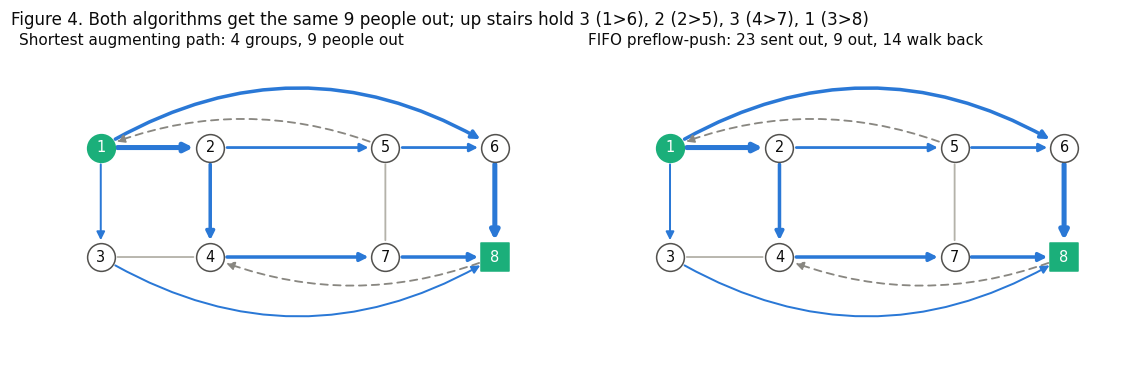

In [14]:
# Figure 4: the mini building, and the people each algorithm sends through it.
MINI_XY = {1: (0, 1), 2: (1, 1), 3: (0, 0), 4: (1, 0), 5: (2.6, 1), 6: (3.6, 1), 7: (2.6, 0), 8: (3.6, 0)}
MINI_BEND = {(1, 6): -0.3, (3, 8): 0.3, (5, 1): 0.2, (8, 4): -0.2}


def draw_mini(ax, people, title):
    for arc in mini.arcs:
        x = people.get((arc.tail, arc.head), 0)
        if arc.capacity == 10 * SCALE and arc.tail > arc.head and not x:
            continue  # draw each idle corridor once
        colour, width = (BLUE, 0.8 + 0.5 * x / SCALE) if x else (ROOM if arc.capacity == 10 * SCALE else MUTED, 1.2)
        ax.annotate("", xy=MINI_XY[arc.head], xytext=MINI_XY[arc.tail], zorder=2,
                    arrowprops=dict(arrowstyle="-|>" if x or arc.capacity < 10 * SCALE else "-", color=colour,
                                    lw=width, shrinkA=11, shrinkB=11, mutation_scale=11,
                                    linestyle="-" if x or arc.capacity == 10 * SCALE else (0, (4, 3)),
                                    connectionstyle=f"arc3,rad={MINI_BEND.get((arc.tail, arc.head), 0)}"))
    for room, (x, y) in MINI_XY.items():
        special = room in (1, 8)
        ax.scatter(x, y, s=330, marker="s" if room == 8 else "o", color=AQUA if special else "white",
                   edgecolor=AQUA if special else INK2, lw=1, zorder=3)
        ax.text(x, y, str(room), ha="center", va="center", fontsize=9.5, zorder=4,
                color="white" if special else INK)
    ax.set_xlim(-0.75, 4.25)
    ax.set_ylim(-0.95, 1.85)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, loc="left", fontsize=10)


def flows(residual, res):
    return {(a.tail, a.head): x for a, x in zip(mini.arcs, arc_flows(residual, res)) if x}


res_sap, res_fifo = mini_residual.fresh(), mini_residual.fresh()
shortest_augmenting_path(mini_residual, res_sap)
preflow_push(mini_residual, res_fifo, rule=FIFO)
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.4))
draw_mini(left, flows(mini_residual, res_sap), "Shortest augmenting path: 4 groups, 9 people out")
draw_mini(right, flows(mini_residual, res_fifo), "FIFO preflow-push: 23 sent out, 9 out, 14 walk back")
fig.suptitle("Figure 4. Both algorithms get the same 9 people out; up stairs hold 3 (1>6), 2 (2>5), 3 (4>7), 1 (3>8)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

## 5. Comparison at the files' own passage order (run in this notebook)

The next cell runs all six settings on all 21 cases, checks every answer, and times each with 5 repeats in one shuffled order (the study used 31). Times depend on the machine running this notebook; work does not.

In [15]:
# The six settings and the timing protocol. Every run's answer is checked before its times count.
SETTINGS = {
    "SAP": partial(shortest_augmenting_path, numb=False),
    "PP-FIFO": partial(preflow_push, rule=FIFO, heuristics=False),
    "SAP+numb": partial(shortest_augmenting_path, numb=True),
    "PP-FIFO+h": partial(preflow_push, rule=FIFO, heuristics=True),
    "PP-HL": partial(preflow_push, rule=HIGHEST, heuristics=False),
    "PP-HL+h": partial(preflow_push, rule=HIGHEST, heuristics=True),
}
REPEATS = 5  # the study used 31 at file order; 5 keeps this notebook to a few minutes


def checked_run(case, setting, residual):
    """One untimed run that must pass every check: the verifier, NetworkX and (dense files) the stairs."""
    res = residual.fresh()
    result = SETTINGS[setting](residual, res)
    check_residual(residual, res)
    check_flow(instances[case], arc_flows(residual, res), result.value)
    assert result.value == reference[case], (case, setting)
    assert case not in stair_sums or result.value == stair_sums[case], (case, setting)
    return result


def run_all(repeats=REPEATS, seed=7372):
    """Warm-up (checked) runs, then all timed repeats in one shuffled order with garbage collection off."""
    rng = random.Random(seed)
    built = {case: build_residual(instances[case]) for case in CASES}
    combos = [(case, setting) for case in CASES for setting in SETTINGS]
    rng.shuffle(combos)
    results = {(case, setting): checked_run(case, setting, built[case]) for case, setting in combos}
    schedule = [combo for combo in combos for _ in range(repeats)]
    rng.shuffle(schedule)
    times = {combo: [] for combo in combos}
    gc.collect()
    gc.disable()
    try:
        for case, setting in schedule:
            res = built[case].fresh()
            start = time.perf_counter()
            result = SETTINGS[setting](built[case], res)
            times[(case, setting)].append(time.perf_counter() - start)
            assert result == results[(case, setting)]  # same answer and counts every time
    finally:
        gc.enable()
    rows = []
    for case in CASES:
        for setting in SETTINGS:
            result = results[(case, setting)]
            counts = asdict(result.counts)
            rows.append({"file": case[0], "reading": case[1], "case": case_label(*case), "setting": setting,
                         "max flow": to_text(result.value), "time_ms": 1000 * statistics.median(times[(case, setting)]),
                         "total_work": counts["checks"] + counts["movements"], **counts})
    return pd.DataFrame(rows)


started = time.perf_counter()
runs = run_all()
print(f"{len(runs)} combinations checked and timed ({REPEATS} repeats each) in {time.perf_counter() - started:.0f} s")

126 combinations checked and timed (5 repeats each) in 195 s


### Shortest augmenting path against FIFO preflow-push

"Faster here" refers to one machine and one passage order only. The zero-flow files take both algorithms hundredths of a millisecond.

In [16]:
# Shortest augmenting path against FIFO preflow-push, at the files' own passage order.
def head_to_head(a, b, frame=None):
    frame = runs if frame is None else frame
    pick = lambda s: frame[frame.setting == s].set_index("case")  # noqa: E731
    A, B = pick(a), pick(b)
    table = pd.DataFrame({
        "max flow": A["max flow"],
        f"{a} ms": A.time_ms.round(2), f"{b} ms": B.time_ms.round(2),
        f"{a} work": A.total_work, f"{b} work": B.total_work,
    })
    table["faster here"] = [a if x < y else b for x, y in zip(A.time_ms, B.time_ms)]
    table.loc[A["max flow"] == "0", "faster here"] = "zero flow"
    return table


head_to_head("SAP", "PP-FIFO")

,max flow,SAP ms,PP-FIFO ms,SAP work,PP-FIFO work,faster here
case,,,,,,
elist96,0,0.02,0.03,4,33,zero flow
elist96d,1.3784,11.78,16.24,86034,101114,SAP
elist160,0,0.02,0.04,3,43,zero flow
elist160d,211.8491,13.10,13.43,88264,83485,SAP
elist200,0,0.02,0.04,7,37,zero flow
elist200d,2.1353,30.03,49.30,232606,262424,SAP
elist500,0,0.02,0.04,3,67,zero flow
elist500d,702.1112,97.84,59.08,503827,326760,PP-FIFO
elist640,0,0.04,0.08,45,259,zero flow


### Where the work goes

For each dense file, the share of a run's work done after the answer was already reached: for SAP, after its last group; for preflow-push, after the last person reaches the exit. Both algorithms do most of their work after that point (58% to 94% for SAP, 65% to 98.5% for FIFO), except on `elist500d`. The speed-ups cut it to at most 7%.

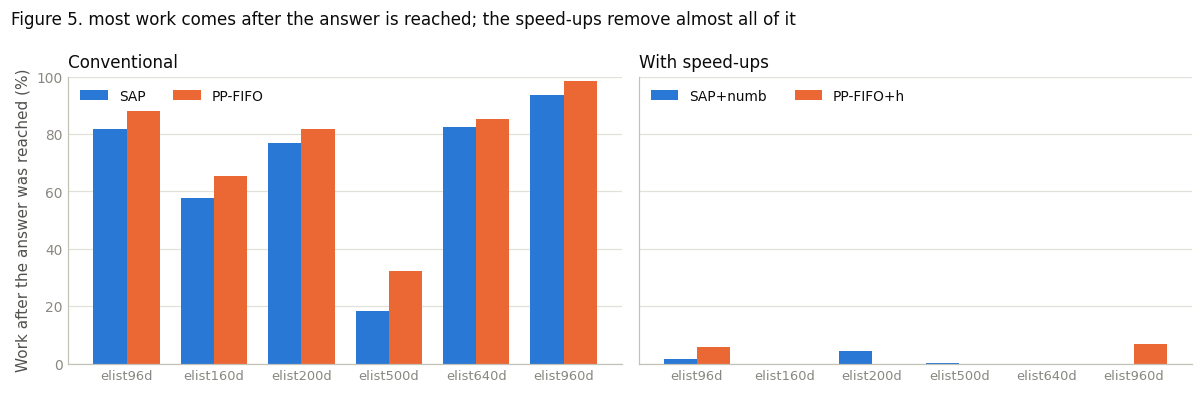

setting,SAP,PP-FIFO,SAP+numb,PP-FIFO+h
file,,,,
elist96d,81.9,87.9,1.5,5.6
elist160d,57.6,65.3,0.0,0.0
elist200d,76.9,81.7,4.5,0.0
elist500d,18.2,32.3,0.1,0.0
elist640d,82.4,85.2,0.1,0.0
elist960d,93.7,98.5,0.0,6.9


In [17]:
# Figure 5: how much of each run's work comes after the answer is already reached (dense files).
def after_share(row):
    if row.setting.startswith("SAP"):
        return row.checks_after_last / row.total_work
    return (row.checks_after_max_preflow + row.pushes_after_max_preflow) / row.total_work


dense = runs[(runs.reading == DIRECTED) & runs.file.isin(DENSE)].copy()
dense["after"] = dense.apply(after_share, axis=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (a, b), title in zip(axes, [("SAP", "PP-FIFO"), ("SAP+numb", "PP-FIFO+h")], ["Conventional", "With speed-ups"]):
    width, xs = 0.38, range(len(DENSE))
    for shift, setting, colour in ((-width / 2, a, BLUE), (width / 2, b, ORANGE)):
        share = [100 * dense[(dense.file == name) & (dense.setting == setting)].after.iloc[0] for name in DENSE]
        ax.bar([x + shift for x in xs], share, width=width, color=colour, label=setting, zorder=2)
    ax.set_xticks(list(xs))
    ax.set_xticklabels(DENSE, fontsize=8.5)
    ax.yaxis.grid(True, color=GRID, zorder=0)
    ax.tick_params(length=0)
    ax.set_ylim(0, 100)
    ax.set_title(title, loc="left")
    ax.legend(loc="upper left", ncol=2, fontsize=9)
axes[0].set_ylabel("Work after the answer was reached (%)")
fig.suptitle('Figure 5. most work comes after the answer is reached; the speed-ups remove almost all of it', x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()
dense.pivot_table(index="file", columns="setting", values="after").loc[list(DENSE), ["SAP", "PP-FIFO", "SAP+numb", "PP-FIFO+h"]].mul(100).round(1)

## 6. Comparison over 30 passage orders (results from the study's GitHub repository)

The order in which each room lists its passages can make either algorithm luckier on the same building. The study therefore ran SAP, PP-FIFO, SAP+numb and PP-FIFO+h again on the 13 cases that carry flow, with 30 shuffled orders, all four settings on the same shuffled building each time. Every run was checked as above and timed with 5 repeats: 7,800 timed runs, 28 minutes on an Apple M2 (24 GB). This section reads those saved results and first confirms that this notebook reproduces the study's operation counts exactly.

**Winner rule, fixed before any results existed.** A setting wins on a building if it is faster in at least 27 of the 30 orders and the median time ratio is at least 1.05. Anything else is "no clear winner". Work is judged the same way, separately.

In [18]:
# Section 6 reads the study's saved M2 results from GitHub (or from a local copy of the repository).
def load(name):
    local = Path("results") / name
    return pd.read_csv(local if local.exists() else f"{RAW}/results/{name}")


m2_base, m2_shuffled = load("runs_baseline.csv"), load("runs_shuffled.csv")
m2_winners, m2_evidence = load("winners.csv"), load("prediction_evidence.csv")
print(f"M2 runs loaded: {len(m2_base)} file-order rows, {len(m2_shuffled)} shuffled-order rows, "
      f"{len(m2_winners)} verdicts ({m2_base.cpu.iloc[0]}, {m2_base.ram_gib.iloc[0]} GiB).")

# Operation counts do not depend on the machine, so this notebook's runs must reproduce them exactly.
COLUMNS = {"checks": "passages_checked", "relabels": "relabels", "movements": "people_movements",
           "total_work": "total_work", "augmentations": "augmentations", "saturating": "saturating_pushes",
           "nonsaturating": "nonsaturating_pushes", "examinations": "room_visits"}
mine = runs.set_index(["file", "reading", "setting"])
theirs = m2_base.set_index(["file", "reading", "setting"]).sort_index()
compared = 0
for key, row in mine.iterrows():
    for ours, column in COLUMNS.items():
        if not pd.isna(row.get(ours)) and not pd.isna(theirs.loc[key, column]):
            assert int(row[ours]) == int(theirs.loc[key, column]), (key, ours)
            compared += 1
print(f"All {compared} operation counts from this notebook match the M2 run exactly.")

M2 runs loaded: 126 file-order rows, 1560 shuffled-order rows, 52 verdicts (Apple M2, 24 GiB).
All 798 operation counts from this notebook match the M2 run exactly.


### Master table

Times (ms) and work are medians over the 30 orders on the M2; the 8 zero-flow files use the study's run at the files' own order. Winners follow the rule above.

- **Time and work disagree on 5 cases**: `elist200d`, `elist640d`, `elist960d`, `elist640` (two-way) and `elist1440` (two-way). The sharpest is `elist1440` (two-way), where SAP does 13% more work but takes 8% less time: preflow-push's steps cost more Python time each.

In [19]:
# The master table: every dataset, medians over the 30 door orders on the M2 (zero-flow files: file order).
def master_table():
    rows = []
    for name, reading in CASES:
        base = theirs.loc[(name, reading)]
        row = {"case": case_label(name, reading), "n": int(base.loc["SAP", "n"]), "m": int(base.loc["SAP", "m"]),
               "max flow": to_text(int(base.loc["SAP", "max_flow_scaled"]))}
        shuffled = m2_shuffled[(m2_shuffled.file == name) & (m2_shuffled.reading == reading)]
        for setting in ("SAP", "PP-FIFO"):
            if len(shuffled):
                per_order = shuffled[shuffled.setting == setting]
                row[f"{setting} ms"] = 1000 * per_order.time_median_s.median()
                row[f"{setting} work"] = int(per_order.total_work.median())
            else:
                row[f"{setting} ms"] = 1000 * base.loc[setting, "time_median_s"]
                row[f"{setting} work"] = int(base.loc[setting, "total_work"])
        verdict = m2_winners[(m2_winners.file == name) & (m2_winners.reading == reading) & (m2_winners.pair == "headline")]
        for measure in ("time", "work"):
            v = verdict[verdict.measure == measure]
            text = v.verdict.iloc[0] if len(v) else "zero flow"
            row[f"winner ({measure})"] = text.removesuffix(" clear win")
        rows.append(row)
    table = pd.DataFrame(rows).set_index("case")
    for column in ("SAP ms", "PP-FIFO ms"):
        table[column] = table[column].map(lambda x: f"{x:,.2f}")
    for column in ("SAP work", "PP-FIFO work"):
        table[column] = table[column].map(lambda x: f"{x:,}")
    return table


master = master_table()
master

,n,m,max flow,SAP ms,SAP work,PP-FIFO ms,PP-FIFO work,winner (time),winner (work)
case,,,,,,,,,
elist96,96,187,0,0.01,4,0.01,33,zero flow,zero flow
elist96d,96,528,1.3784,6.80,"86,412",9.29,"108,574",SAP,SAP
elist160,160,285,0,0.01,3,0.01,43,zero flow,zero flow
elist160d,160,912,211.8491,7.48,"85,768",6.66,"75,920",PP-FIFO,PP-FIFO
elist200,200,483,0,0.01,7,0.01,37,zero flow,zero flow
elist200d,200,1340,2.1353,16.99,"232,229",20.05,"257,409",SAP,no clear winner
elist500,500,1040,0,0.01,3,0.02,67,zero flow,zero flow
elist500d,500,3975,702.1112,43.23,"488,868",25.63,"305,072",PP-FIFO,PP-FIFO
elist640,640,3037,0,0.01,45,0.03,259,zero flow,zero flow


### Who wins, order by order

Each dot is one passage order; the diamond is the files' own order.

- **SAP wins 10 of 13.** Both algorithms waste most of their effort after the answer (Figure 5), and SAP's simpler steps cost less.
- **Preflow-push wins `elist500d` and `elist160d`**, where SAP takes 72% and 11% longer; SAP also does 59% and 12% more work there.
- **With speed-ups, preflow-push wins all 6 dense files and 3 two-way cases**; SAP+numb wins `elist160` and `elist200` (two-way).
- **One order can mislead:** for `elist960` (two-way) with speed-ups, the files' own order lies outside all 30 shuffled orders.

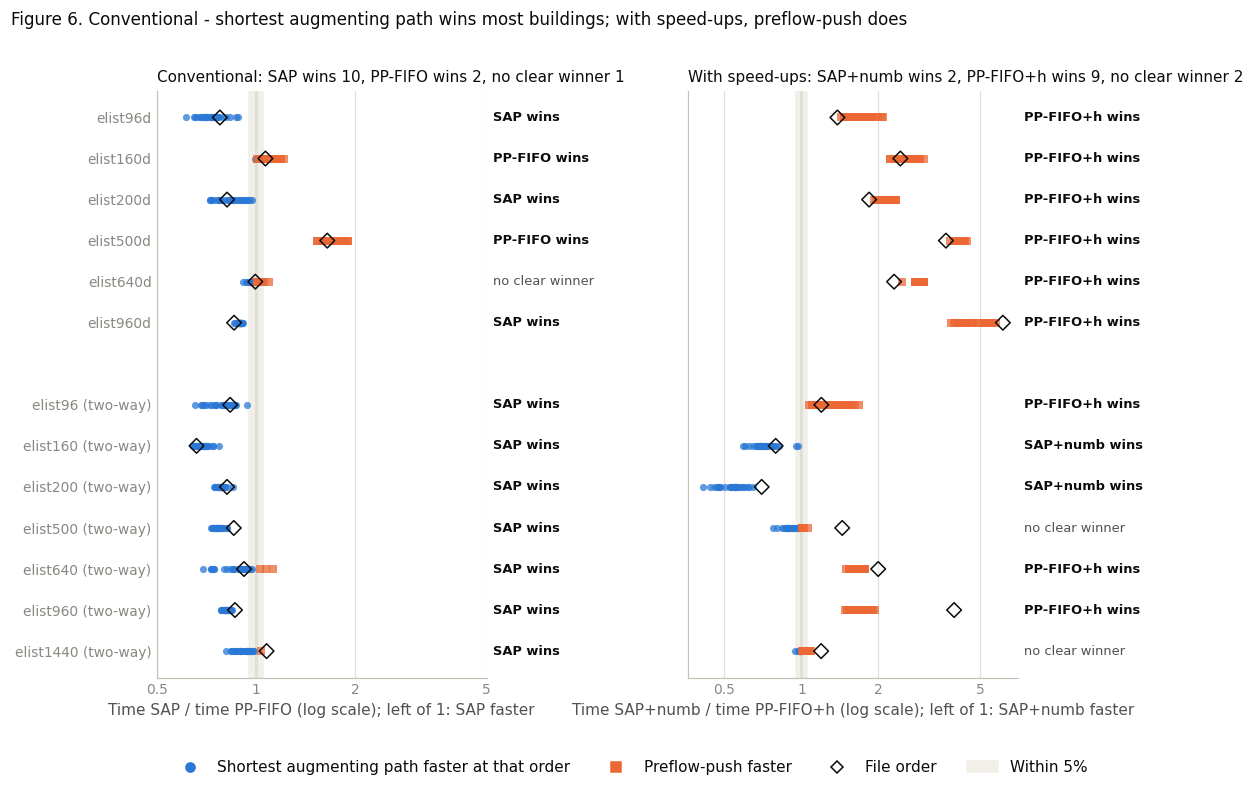

In [20]:
# Figure 6: who wins at each of the 30 door orders, conventional and with speed-ups.
FLOW_CASES = [(name, DIRECTED) for name in DENSE] + [(name, TWO_WAY) for name in SPARSE]
PAIRS = {"headline": ("SAP", "PP-FIFO"), "tuned": ("SAP+numb", "PP-FIFO+h")}


def per_order(name, reading, setting, column="time_median_s"):
    rows = m2_shuffled[(m2_shuffled.file == name) & (m2_shuffled.reading == reading) & (m2_shuffled.setting == setting)]
    return rows.sort_values("arc_order")[column].to_numpy()


def verdict_of(name, reading, pair, measure="time"):
    w = m2_winners
    return w[(w.file == name) & (w.reading == reading) & (w.pair == pair) & (w.measure == measure)].verdict.iloc[0]


fig, axes = plt.subplots(1, 2, figsize=(11.5, 7), sharey=True)
ys = {case: k + (1 if case[1] == TWO_WAY else 0) for k, case in enumerate(FLOW_CASES)}
for ax, (pair, (a, b)) in zip(axes, PAIRS.items()):
    counts = {a: 0, b: 0, "none": 0}
    for case in FLOW_CASES:
        ratios = per_order(*case, a) / per_order(*case, b)
        y = ys[case]
        ax.scatter(ratios[ratios < 1], [y] * (ratios < 1).sum(), s=22, color=BLUE, marker="o", alpha=0.75, lw=0, zorder=3)
        ax.scatter(ratios[ratios >= 1], [y] * (ratios >= 1).sum(), s=22, color=ORANGE, marker="s", alpha=0.75, lw=0, zorder=3)
        file_order = theirs.loc[(*case, a), "time_median_s"] / theirs.loc[(*case, b), "time_median_s"]
        ax.scatter([file_order], [y], s=46, facecolor="none", edgecolor=INK, marker="D", lw=1, zorder=4)
        v = verdict_of(*case, pair)
        key = a if v.startswith(a + " ") else b if v.startswith(b + " ") else "none"
        counts[key] += 1
        ax.text(1.02, y, f"{key} wins" if key != "none" else "no clear winner", transform=ax.get_yaxis_transform(),
                va="center", fontsize=8.5, color=INK if key != "none" else INK2,
                fontweight="bold" if key != "none" else "normal")
    ax.axvspan(1 / 1.05, 1.05, color=BAND, zorder=0)
    ax.axvline(1, color=INK2, lw=0.8, zorder=1)
    ax.set_xscale("log")
    ax.set_xticks([0.5, 1, 2, 5])
    ax.set_xticklabels(["0.5", "1", "2", "5"])
    ax.minorticks_off()
    ax.xaxis.grid(True, color=GRID, zorder=0)
    ax.tick_params(length=0)
    ax.set_title(f"{'Conventional' if pair == 'headline' else 'With speed-ups'}: {a} wins {counts[a]}, "
                 f"{b} wins {counts[b]}, no clear winner {counts['none']}", loc="left", fontsize=10)
    ax.set_xlabel(f"Time {a} / time {b} (log scale); left of 1: {a} faster")
axes[0].set_yticks(list(ys.values()))
axes[0].set_yticklabels([case_label(*case) for case in FLOW_CASES])
axes[0].invert_yaxis()
handles = [plt.Line2D([], [], ls="", marker="o", color=BLUE, label="Shortest augmenting path faster at that order"),
           plt.Line2D([], [], ls="", marker="s", color=ORANGE, label="Preflow-push faster"),
           plt.Line2D([], [], ls="", marker="D", markerfacecolor="none", markeredgecolor=INK, label="File order"),
           plt.Rectangle((0, 0), 1, 1, color=BAND, label="Within 5%")]
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Figure 6. Conventional - shortest augmenting path wins most buildings; with speed-ups, preflow-push does",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0.04, 0.92, 0.97), w_pad=6)
plt.show()

### What the speed-ups change

On the dense files, the speed-ups cut preflow-push's time 2.8 to 57 times and SAP's 1.2 to 11 times. Preflow-push gains more because gap and global relabeling correct many labels at once throughout the run, while `numb` only stops SAP's work after its last group (a `numb` run is exactly the first part of a conventional run).

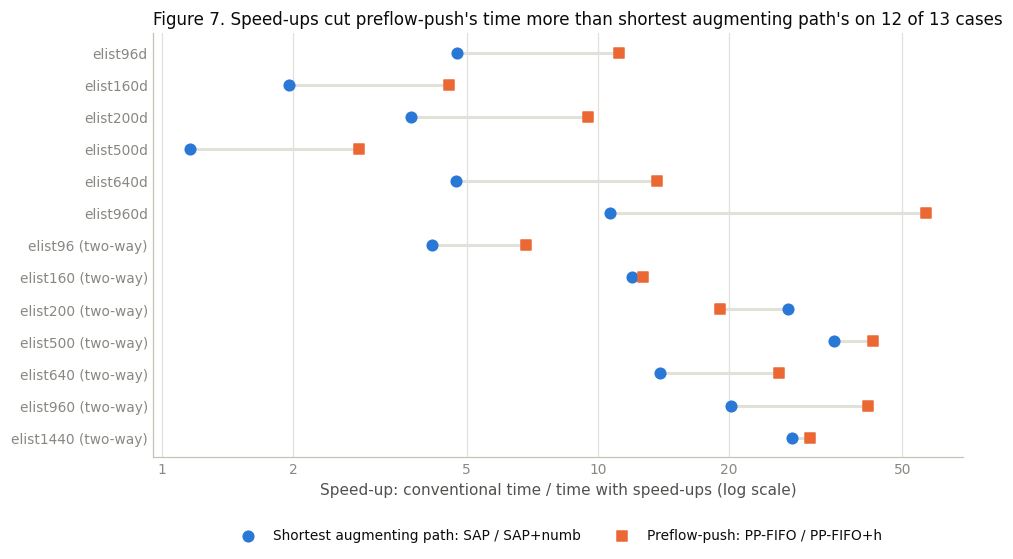

,SAP,PP-FIFO
case,,
elist96d,4.8,11.2
elist160d,2.0,4.5
elist200d,3.7,9.5
elist500d,1.2,2.8
elist640d,4.7,13.7
elist960d,10.7,56.7
elist96 (two-way),4.2,6.8
elist160 (two-way),12.0,12.7
elist200 (two-way),27.3,19.1


In [21]:
# Figure 7: how much each algorithm's speed-ups cut its time (median over the 30 door orders).
speedup = pd.DataFrame([{
    "case": case_label(*case),
    "SAP": statistics.median(per_order(*case, "SAP") / per_order(*case, "SAP+numb")),
    "PP-FIFO": statistics.median(per_order(*case, "PP-FIFO") / per_order(*case, "PP-FIFO+h")),
} for case in FLOW_CASES]).set_index("case")
fig, ax = plt.subplots(figsize=(9.5, 5))
ys = list(range(len(speedup)))
for y, (case, row) in zip(ys, speedup.iterrows()):
    ax.plot([row.SAP, row["PP-FIFO"]], [y, y], color=GRID, lw=2, zorder=1)
ax.scatter(speedup.SAP, ys, color=BLUE, s=48, marker="o", label="Shortest augmenting path: SAP / SAP+numb", zorder=2)
ax.scatter(speedup["PP-FIFO"], ys, color=ORANGE, s=48, marker="s", label="Preflow-push: PP-FIFO / PP-FIFO+h", zorder=2)
ax.set_xscale("log")
ax.set_xticks([1, 2, 5, 10, 20, 50])
ax.set_xticklabels(["1", "2", "5", "10", "20", "50"])
ax.minorticks_off()
ax.set_yticks(ys)
ax.set_yticklabels(speedup.index)
ax.invert_yaxis()
ax.xaxis.grid(True, color=GRID, zorder=0)
ax.tick_params(length=0)
ax.set_xlabel("Speed-up: conventional time / time with speed-ups (log scale)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)
more = (speedup["PP-FIFO"] > speedup.SAP).sum()
ax.set_title(f"Figure 7. Speed-ups cut preflow-push's time more than shortest augmenting path's on {more} of 13 cases",
             loc="left")
plt.show()
speedup.round(1)

## 7. Conclusion

- **Conventional shortest augmenting path is the better choice on networks like these.** It was clearly faster on 10 of the 13 cases that carry flow, taking 8% to 32% less time.
- **With the standard speed-ups, preflow-push (FIFO with gap and global relabeling) is the better choice.** It was clearly faster on all 6 dense files, where SAP with `numb` took 1.7 to 4.7 times as long, and on 9 of 13 cases overall.
- **The speed-ups matter more than the choice of algorithm.** They cut times by up to 57 times, while the two algorithms conventionally were never more than a factor of 1.72 apart.
- **Worst-case bounds were a poor guide.** They favour FIFO by a factor of 5.5 to 19.7 on the dense files, yet FIFO, conventional, won only 2 of them.

**Limits.**

- One family of synthetic networks; only 6 files carry flow as given, plus 7 two-way readings.
- Pure Python on one machine: times include interpreter overhead, so work counts are reported alongside.
- Conclusions hold per building, for these networks; they are not a general ranking.

## Appendix A. Full tables

All six settings at the files' own order (this notebook, median ms), then all 52 verdicts over the 30 orders on the M2.

In [22]:
# Appendix A: all six settings at file order in this notebook (median ms of the repeats, this machine).
runs.pivot_table(index="case", columns="setting", values="time_ms", sort=False)[list(SETTINGS)].round(2)

setting,SAP,PP-FIFO,SAP+numb,PP-FIFO+h,PP-HL,PP-HL+h
case,,,,,,
elist96,0.02,0.03,0.02,0.03,0.07,0.08
elist96d,11.78,16.24,2.67,2.10,16.74,1.46
elist160,0.02,0.04,0.03,0.03,0.10,0.11
elist160d,13.10,13.43,6.97,3.05,13.12,2.70
elist200,0.02,0.04,0.03,0.05,0.08,0.10
elist200d,30.03,49.30,8.71,5.56,49.48,5.15
elist500,0.02,0.04,0.05,0.07,0.24,0.22
elist500d,97.84,59.08,90.17,24.58,45.96,23.73
elist640,0.04,0.08,0.07,0.11,0.28,0.28


In [23]:
# All 52 verdicts over the 30 door orders on the M2 (ratio: first setting / second, median).
m2_winners.assign(case=[case_label(f, r) for f, r in zip(m2_winners.file, m2_winners.reading)],
                  wins=[f"{a}-{b}" for a, b in zip(m2_winners.a_wins, m2_winners.b_wins)]) \
    .pivot_table(index="case", columns=["pair", "measure"], values=["verdict"], aggfunc="first", sort=False)

verdict                                                             
pair                          headline                                   tuned                     
measure                           time               work                 time                 work
case                                                                                               
elist96d                 SAP clear win      SAP clear win  PP-FIFO+h clear win  PP-FIFO+h clear win
elist160d            PP-FIFO clear win  PP-FIFO clear win  PP-FIFO+h clear win  PP-FIFO+h clear win
elist200d                SAP clear win    no clear winner  PP-FIFO+h clear win  PP-FIFO+h clear win
elist500d            PP-FIFO clear win  PP-FIFO clear win  PP-FIFO+h clear win  PP-FIFO+h clear win
elist640d              no clear winner  PP-FIFO clear win  PP-FIFO+h clear win  PP-FIFO+h clear win
elist960d                SAP clear win    no clear winner  PP-FIFO+h clear win  PP-FIFO+h clear win
elist96 (two-way)        SAP clear win      SAP clear win  PP-FIFO+h clear win  PP-FIFO+h clear win
elist160 (two-way)       SAP clear win      SAP clear win   SAP+numb clear win   SAP+numb clear win
elist200 (two-way)       SAP clear win      SAP clear win   SAP+numb clear win   SAP+numb clear win
elist500 (two-way)       SAP clear win      SAP clear win      no clear winner      no clear winner
elist640 (two-way)       SAP clear win    no clear winner  PP-FIFO+h clear win  PP-FIFO+h clear win
elist960 (two-way)       SAP clear win      SAP clear win  PP-FIFO+h clear win  PP-FIFO+h clear win
elist1440 (two-way)      SAP clear win  PP-FIFO clear win      no clear winner      no clear winner

## Appendix B. Reproducing the study, and references

- **The full study** ([repository](https://github.com/absharotry/mmie.7372.001.NetFlow-DyProg.fall26/tree/main/computational-study-2)): `pytest -q` (828 tests), `python scripts/run_benchmark.py` (all six settings, 31 repeats, 8 minutes), then `python scripts/run_shuffles.py` and `python scripts/compare_orders.py` (30 orders, 28 minutes).

**References**

- Ahuja, R. K., Magnanti, T. L., and Orlin, J. B. (1993). *Network Flows: Theory, Algorithms, and Applications.* Prentice Hall. Sections 2.4, 6.3–6.5 and 7.4–7.8.
- Hagberg, A. A., Schult, D. A., and Swart, P. J. (2008). Exploring network structure, dynamics, and function using NetworkX. *Proceedings of the 7th Python in Science Conference*, 11–15.